The local hazard asks whether the **next selected action** fails. Residual
risk adds the probability of eventual loss after that action succeeds, completing
the modular framework toward a forward **individual-possession xLoss**. This
component is now a main vignette, immediately after hazard and bands. It remains
optional when the objective is current pressure or action difficulty.

## Conditional target and completion to xLoss

Let $Y=1$ mean a failed terminal pass, individual `possession_loss`, or clearance.
A completed pass or foul suffered has $Y=0$; shot-ending possessions are excluded.
This label is defined for individual control and does not always equal a team
turnover. No additional OBE filter is applied to this terminal-outcome cohort.

$$c(s_t)=P(Y=1\mid s_t,\ \mathrm{carry\ selected\ and\ successful\ for\ 1s}).$$

Inputs describe the frame $t$, not the observed state after the successful carry.
With $p=P(\mathrm{pass}\mid s)$, carry loss $d$, and destination-weighted pass
failure $f=\sum_jq_j(1-p_j)$:

$$h(s)=pf+(1-p)d,$$
$$xLoss(s)=pf+(1-p)\{d+(1-d)c(s)\}=h(s)+(1-p)(1-d)c(s).$$

A successful pass ends this individual's possession. There is no continuation
on a teammate's later control. This is a project-specific xLoss definition, not
a claim to reproduce SkillCorner's proprietary estimator. The composed xLoss
has not itself received a held-out calibration evaluation: the results below
evaluate **c only**. Composition follows total probability; its component models
remain approximations of conditional execution and average policy. **own derivation**

## Native likelihood and cohort

Native XGBoost `binary:logistic` minimizes Bernoulli NLL plus tree regularization
with **loss=1**, reversing the old historical success-positive label
[@chen2016xgboost]. There are no custom derivatives, monotonicity constraints,
class weights or resampling. Training contains **8,672 successful canonical
one-second carries, 1,928 terminal losses (22.23%)**, from ten matches.
Outfield/no-shot, matched individual endpoints and usable current states apply.
Short successful tails and current failed carries are outside this conditional
cohort. The 8,541 former valid rows retain their labels after polarity reversal;
131 otherwise valid unknown-context rows are recovered. Counts are states,
not unique possessions; long possessions contribute multiple states.

## Features and meanings




The final evaluated specification has **31 conceptual inputs: 29 numeric and
two raw categorical labels**. One-hot vocabulary is learned on fitting matches
only, with explicit missing and unseen levels. Granular start/previous labels
are retained, including literal `unknown`. The exact per-fold schemas are
[downloadable](../../data/benchmarks/action_selection/feature_schemas.json).

### 1. Context: five inputs

| Input | Definition |
|---|---|
| Start type | Raw event label for how this individual control began: reception, interception, recovery, restart, etc. |
| Previous action | Start context until a complete one-second carry has occurred; `ball_drive` thereafter. |
| Match minute | Match clock at the evaluated frame. |
| Score difference | Carrier-team goals minus opponent goals, using score changes known by that frame. |
| Elapsed individual-possession time | Seconds from individual control start to the CURRENT frame; replaces the whole-carry count. |

Elapsed time is known at prediction. In this conditional terminal task it is
not a proxy for choosing pass versus canonical carry. Final possession length,
remaining time and observed future tracking are excluded. All labels are the
terminal outcome of the individual possession, not the next action alone.

### 2. Carrier and pressure: six inputs

| Input | Definition |
|---|---|
| Carrier x | Current longitudinal coordinate oriented toward its team's attack. |
| Carrier y | Current lateral coordinate under the same 180° orientation transform. |
| Carrier speed | Norm of current tracked velocity. |
| Velocity angle | Angle of velocity relative to attack, missing when effectively stationary. |
| Carry success | $D(s)=1-P(\mathrm{loss\ within\ 1s}\mid\mathrm{carry},s)$ from the physical likelihood. |
| BCOS | Probability-weighted accessible area in m² within 40 m, with arrival dispersion from the matching carry fit. |

The motion input is the existing centred seven-frame velocity estimate. The
carrier's local one-second projection is $x_B(1)=x_B(0)+v_B(0)$; no future
observed trajectory or observed acceleration is supplied. This is offline
evaluation: centred velocity smoothing has three future frames of support.
The [carry vignette](../01_ball_drive_risk/01_ball_drive_risk.ipynb) explains
the likelihood, and the [BCOS vignette](../extras/bcos/10_bcos.ipynb) introduces
the open-space concept [@bandara2025bcos]. Benchmark BCOS uses a 1 m target grid,
0.03125 m path spacing and 0.04 s integration, with carrier cap 6.6 m/s,
defender cap 7 m/s and linear/turning acceleration 7 m/s². The small-domain API
example below is a fast demonstration; its grid differs from this cache.

### 3. Spatial and tactical state: eight inputs

Set $z=x_B(0)+v_B(0)\,1\mathrm{s}$. Lines are inferred from the **current**
tracked configuration; the projection does not use future observed positions.

| Input | Definition |
|---|---|
| Team xT after carry | Own-oriented xT at $z$. |
| Opponent xT after carry | Opponent-oriented xT at the same hypothetical point. |
| Team line index after carry | Nearest own-team line index at $z$. |
| Opponent line index after carry | Nearest opposition line index at $z$. |
| Team line distance after carry | Signed longitudinal distance from $z$ to the nearest own line; positive ahead in the carrier attack direction. |
| Opponent line distance after carry | Corresponding distance to the nearest opposition line. |
| Teammates ahead of carrier | Current teammates beyond the transverse line through the **current carrier**. |
| Opponents ahead of carrier | Current opponents beyond that same transverse line. |

Pressure lines use three complete-linkage clusters of longitudinal positions,
after removing padding and the historical extreme-x goalkeeper proxy. Their
nearest-centre indices are 1–3. Opponent indices follow the carrier attack axis;
own indices retain the opposite-axis convention shared with pass selection.
Both signed distances use the carrier attack axis. This line representation
is motivated by Fernández's feature family and aligned across this project
[@fernandez2021]. xT uses a smoothed 10×6 surface fitted to the same six matches
as the action classifier [@singh2018xt].

For a roster $G$ and point $z$, the ahead count is

$$N_G(z)=\sum_{i\in G}\mathbf1\{d x_i>d z_x\},\quad d\in\{-1,+1\}.$$

The carrier team's attack direction is used for **both rosters**. Exclude the
carrier and padding; retain tracked goalkeepers. Equality is not counted.
These are counts beyond a point, not players between pass origin and target.
A backward target can therefore have more players ahead.

### 4. Hypothetical passing options: eleven inputs

For each destination $j$ on the native one-metre pitch grid:

* $q_j=P(j\mid\mathrm{pass},s)$ comes from the flat destination-choice model,
  with its validation temperature. Its internal control feature is **raw**.
* $p_j=P(\mathrm{completion\ at}\ j\mid s)$ comes from pass physics **followed
  by isotonic calibration**. This action model uses calibrated pass risk, not
  raw pitch control, in its option summaries [@spearman2017; @spearman2018beyond].

Define $w_j^+=q_jp_j$ and $w_j^-=q_j(1-p_j)$.

| Input | Formula and meaning |
|---|---|
| Expected pass success | $\sum_jw_j^+$: completion averaged over likely destinations. |
| Team xT on success | $\sum_jw_j^+X_{own}(j)$: own threat retained through a completed pass. |
| Opponent xT on failure | $\sum_jw_j^-X_{opp}(j)$: opponent threat exposed by an unsuccessful pass. |
| Team line on success | $\sum_jw_j^+L_{own}(j)$: own-line location reached by likely completed passes. |
| Team line on failure | $\sum_jw_j^-L_{own}(j)$: own-team structure at hypothetical failed-pass destinations. |
| Opponent line on success | $\sum_jw_j^+L_{opp}(j)$: opposition pressure-line location reached on success. |
| Opponent line on failure | $\sum_jw_j^-L_{opp}(j)$: opposition line associated with the hypothetical failure location. |
| Teammates ahead on success | $\sum_jw_j^+N_{own}(j)$: teammates remaining beyond likely completed-pass destinations. |
| Teammates ahead on failure | $\sum_jw_j^-N_{own}(j)$: teammates beyond hypothetical failed-pass destinations. |
| Opponents ahead on success | $\sum_jw_j^+N_{opp}(j)$: opposition positioning beyond likely completed-pass destinations. |
| Opponents ahead on failure | $\sum_jw_j^-N_{opp}(j)$: opposition positioning beyond hypothetical failed-pass destinations. |

The four line and four count inputs are the agreed **4+4**. Each spatial value
is evaluated at a hypothetical target using current player locations, including
the failure branch. No observed recovery point is an input. **Do not divide by
total success/failure probability**: these are joint outcome-weighted summaries,
so branch probability is deliberately retained. **design choice**


### 5. Action tendency: one input

`action_carry_probability` is native $P(\mathrm{carry}\mid s)$ from the matching
action-selection model. It describes average behaviour at the current state,
not the realized future action. Its added OOF gain is only 0.083 percentage points.


## Executable composition example

Synthetic probabilities illustrate the additional continuation term; these are not fitted predictions.

Local hazard: 0.14
Terminal loss with c=0.3: 0.30200000000000005


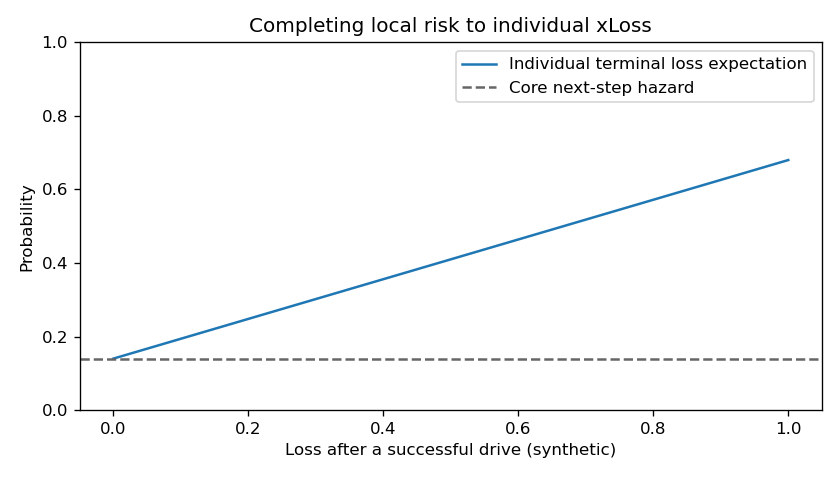

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PRESS.extras import compose_individual_xloss

# Illustrative probabilities, not learned predictions or performance results.
p_pass, drive_loss, pass_failure = 0.4, 0.1, 0.2
residual_loss = np.linspace(0, 1, 101)
hazard = p_pass * pass_failure + (1-p_pass) * drive_loss
xloss = compose_individual_xloss(p_pass=p_pass, drive_loss=drive_loss,
    pass_failure=pass_failure, residual_loss=residual_loss)
assert np.isclose(xloss[0], hazard)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(residual_loss, xloss, label="Individual terminal loss expectation")
ax.axhline(hazard, color="0.4", linestyle="--", label="Core next-step hazard")
ax.set(xlabel="Loss after a successful drive (synthetic)", ylabel="Probability",
       ylim=(0, 1), title="Completing local risk to individual xLoss")
ax.legend(); fig.tight_layout()
out = Path("figures/vignette_12_residual_risk.png")
out.parent.mkdir(exist_ok=True)
fig.savefig(out, dpi=150); fig.savefig(out.with_suffix(".svg"))
print("Local hazard:", hazard)
print("Terminal loss with c=0.3:", compose_individual_xloss(
    p_pass=p_pass, drive_loss=drive_loss, pass_failure=pass_failure, residual_loss=0.3))


## Training, validation and held-out results

Each outer fold uses **6 fit + 2 validation + 2 test matches**. Physical carry,
pass, flat choice, xT and BCOS summaries use the same-fold upstream stack.
Validation/test `P(carry)` uses its exact matching AS70 model. Within the six
fitting matches, three fixed AS refits each train on four matches and score the
omitted two, preventing training-row action predictions from using their own
action labels. This inner step cross-fits action weights; its physical summaries
remain frozen from the outer six-fit stack. The validation pair also supports
upstream calibration and model selection. This is a development evaluation on
ten studied matches, not fully independent nested validation or an external test.

The complete grid is depth {3,4,6,8}, child weight {1,5,20}, L2 {0.1,1,3,10}
and eta {0.03,0.05,0.1}: **144 configurations × two variants × five folds =
1,440 fits**. Row/column subsampling are 0.8, hist bins256, tree cap2000,
early stopping100. Validation NLL chooses the configuration and tree prefix
before opening the outer test. Every fit stops below the cap.

One positive temperature is subsequently fitted by validation-only Bernoulli
MLE on the frozen selected ensemble, without an intercept or test-ECE selection
[@guo2017calibration]. Native output is retained: scaling does not improve pooled
CE. The augmented native model yields **CE0.472396, null CE0.530519,
gain10.956%, Brier0.152338, AUC0.72810 and ECE1.155%**. Adding action tendency
improves gain by only0.083 percentage points; the base is practically equivalent.

![Five-fold pooled residual-risk calibration, ten equal-count bins. Native and temperature-scaled curves are evaluated on the same held-out states.](../../figures/residual_risk_pooled_calibration.png)

## Remaining-time diagnostic

Remaining time is evaluated **retrospectively**, never used as a predictor.
From the current frame it is `individual_end − current_frame`. Pass endings
occur at release, not reception. With a successful full second required, the
minimum remaining time in this cohort is1s. From1–2s to2–3s and3–5s, base gain
against a six-fit subgroup null is12.51%,10.85%,5.97%. The broad ≥5s tail rises
to15.38%, but its480 states represent only257 possessions. Giving each possession
equal weight reduces that tail gain to8.80%; it is not evidence that longer
horizons intrinsically predict better. Fixed one-second bins and weighting
sensitivity are documented in the [benchmark](../../benchmark.qmd#residual-risk-benchmark).

## Related work and scope

No directly comparable published numerical benchmark was found in the targeted
literature search (29October2026). Gu et al. predict team retention at a four-second
horizon using PPM sequences, with Table1 accuracy55.8%/75.2%/78.7% for tracking,
2D PPM and3D PPM, respectively [@gu2024pressure]. Dick and Brefeld model next-action
rates and direct loss before passing, with time-dependent turnover hit rates
[@dick2023actionrate]. These motivate pressure and turnover prediction but do
not evaluate conditional terminal individual loss after a successful1s carry.
Semi-Markov temporal xT targets team goals, not this label [@lecoz2026semimarkov].
See the [source/target comparison](../../data/benchmarks/residual_risk/related_literature.csv).


In [7]:
import pandas as pd
pd.read_csv("data/benchmarks/residual_risk/pooled_metrics.csv")

## Use the installed deployment model

The package contains the verified full-data native model
`skillcorner_outfield_residual_risk_v1`:129trees and31conceptual inputs, with
no scaling. The next cell computes residual risk and individual xLoss on a
synthetic tracking state using the actual installed reader and weights.
Small demonstration grids differ from production and do not produce benchmark
scores. The result is a hypothetical continuation forecast, not knowledge of
what happens after the selected frame.

Capacity is chosen from mean validation CE across the five RR74 grids: depth4,
child1,L2=10,eta0.03. For that same configuration the best prefixes are
114/154/183/98/129, fixing129trees by their median. The full-data refit reuses
the verified AS73 physical/pass/choice/xT/BCOS cache. Five eight-fit/two-omitted
AS refits provide training P(carry); at inference the installed all-ten-match
AS73 model supplies this input. Refit training scores are not benchmark scores.
[Deployment provenance](../../docs/residual-risk-refit-provenance.json).


In [9]:
from pathlib import Path
import numpy as np
import pandas as pd
from PRESS.model import ActionSelectionModel, ResidualRiskModel
from PRESS.datasets import load_demo_match
from PRESS import PRESS
from PRESS.extras import BCOS, compose_individual_xloss

tracking, possessions, actions, xt = load_demo_match()
press = PRESS(tracking, possessions_data=possessions, actions_data=actions)
frame = 5
area = float(BCOS(tracking).compute_bcos(frame, r_max=8, step=4)["BCOS area"])
result = press.compute_frame(frame, xt, bcos_value=area, ppcf_kwargs={"r_max":12,"step":6})
state, context = press.get_state(frame), press.get_frame_context(frame)
action_model = ActionSelectionModel.pretrained()
residual_model = ResidualRiskModel.pretrained()
field = result["PPCF"]
elapsed = 0.5  # synthetic fixture: frame5 is0.5s after control starts
record = action_model.build_feature_record(
    x_bc=state["x_bc"], v_bc=state["v_bc"], r_atts=state["r_atts"], r_defs=state["r_defs"],
    attacking_side=state["attacking_side"], targets=field["grid"],
    transition_probabilities=field["Transition probabilities"],
    pass_success_probability=field["Pass probability"], bcos=area,
    ball_drive_loss=result["PI"]["Ball drive loss probability"],
    start_type_raw=context["start_type"], previous_action_raw=context["previous_action"],
    match_clock_min=tracking.loc[tracking.frame.eq(frame), "match_clock_min"].iloc[0],
    score_difference_prefix=0., completed_canonical_drives=0,
    pitch_length=state["pitch_length"], pitch_width=state["pitch_width"])
matrix = residual_model.features_from_action_record(record, time_since_start=elapsed, action_model=action_model)
c = float(residual_model.predict_features(matrix)[0])
p = float(action_model.predict_features(action_model.encode(pd.DataFrame([record])))[0])
d = float(result["PI"]["Ball drive loss probability"])
f = float(np.sum(np.asarray(field["Transition probabilities"])*(1-np.asarray(field["Pass probability"]))))
h = p*f + (1-p)*d
continuation = (1-p)*(1-d)*c
print("Residual loss after a successful carry:", c)
print("Local next-action hazard:", h)
print("Additional terminal continuation:", continuation)
print("Individual xLoss:", compose_individual_xloss(p_pass=p, drive_loss=d, pass_failure=f, residual_loss=c))

assert np.isclose(compose_individual_xloss(p_pass=p, drive_loss=d, pass_failure=f, residual_loss=c), h+continuation)


Residual loss after a successful carry: 0.09284597635269165
Local next-action hazard: 0.012514264786956204
Additional terminal continuation: 0.04742897684966011
Individual xLoss: 0.059943241636616316
